# Portafolio 3/3 · Clustering: segmentar clientes por hábitos de compra

Tercer modelo del portafolio. Aquí **no hay etiqueta**, así que no hay línea base que "acierte" ni exactitud que medir. La comparación cambia de naturaleza:

1. Elegir el número de clústeres `k` (el ejercicio usa la opción *Automático*; aquí se hace explícito).
2. Comparar dos algoritmos, **K-Means** y **agrupación jerárquica**, con la **silueta**.
3. Calcular para el modelo elegido las métricas de separación del módulo 7: distancia media al centro, distancia media a los otros centros, distancia máxima al centro y silueta.
4. Asignar los dos clientes de prueba del ejercicio.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples

SEMILLA = 42
clientes = pd.read_csv('../datasets/customers.csv')
features = ['AverageSpend', 'AverageFrequency']
print(f'{len(clientes)} clientes')
clientes[features].describe().round(2)

40 clientes


,AverageSpend,AverageFrequency
count,40.00,40.00
mean,57.58,28.01
std,30.10,18.69
min,15.00,5.00
25%,28.75,9.95
50%,63.00,28.50
75%,86.25,46.28
max,95.00,50.00


## Escalado

Ambos algoritmos agrupan por **distancia**. El gasto va de 15 a 95 y la frecuencia de 5 a 50: sin escalar, la feature de rango mayor pesaría más en la distancia y decidiría casi sola los grupos.

In [2]:
escala = StandardScaler()
X = escala.fit_transform(clientes[features])

## Elegir `k` y comparar algoritmos

Para cada `k` de 2 a 7 se entrenan los dos algoritmos y se mide la silueta. Para K-Means se añade también la curva del codo (WCSS).

In [3]:
ks = range(2, 8)
filas = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    jer = AgglomerativeClustering(n_clusters=k).fit(X)
    filas.append({'k': k, 'WCSS (K-Means)': km.inertia_,
                  'Silueta K-Means': silhouette_score(X, km.labels_),
                  'Silueta jerárquica': silhouette_score(X, jer.labels_)})
tabla_k = pd.DataFrame(filas).set_index('k')
tabla_k.round(3)

,WCSS (K-Means),Silueta K-Means,Silueta jerárquica
k,,,
2,40.701,0.503,0.503
3,20.529,0.635,0.635
4,3.033,0.810,0.810
5,1.793,0.767,0.767
6,1.513,0.655,0.664
7,1.238,0.543,0.658


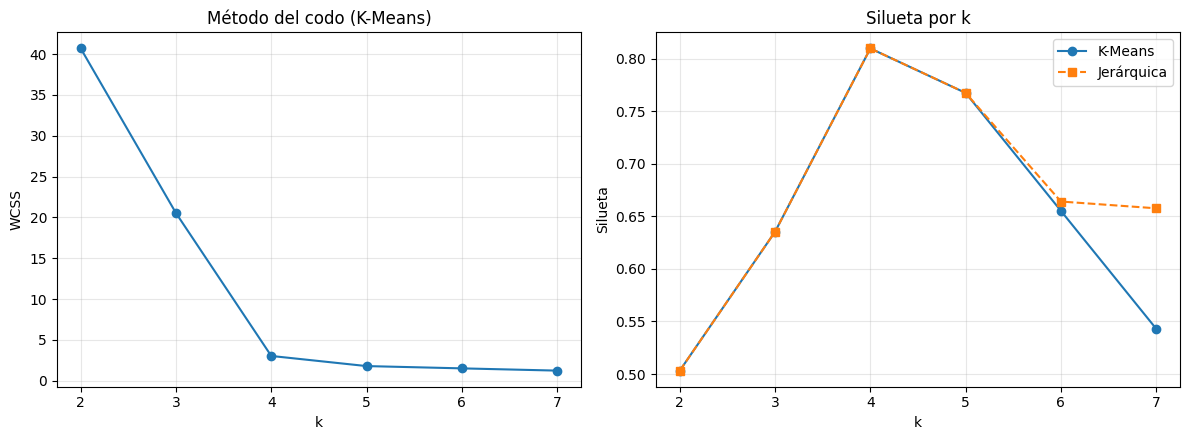

k con mayor silueta (K-Means): 4


In [4]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 4.5))
izq.plot(tabla_k.index, tabla_k['WCSS (K-Means)'], 'o-')
izq.set_title('Método del codo (K-Means)')
izq.set_xlabel('k'); izq.set_ylabel('WCSS'); izq.grid(alpha=0.3)
der.plot(tabla_k.index, tabla_k['Silueta K-Means'], 'o-', label='K-Means')
der.plot(tabla_k.index, tabla_k['Silueta jerárquica'], 's--', label='Jerárquica')
der.set_title('Silueta por k')
der.set_xlabel('k'); der.set_ylabel('Silueta'); der.legend(); der.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../imagenes/clustering-codo-y-silueta.png', dpi=110, bbox_inches='tight')
plt.show()

k_mejor = int(tabla_k['Silueta K-Means'].idxmax())
print(f'k con mayor silueta (K-Means): {k_mejor}')

## ¿Encuentran los dos algoritmos los mismos grupos?

Con el `k` elegido, se cruzan las asignaciones de ambos. Los números de clúster son arbitrarios (el "0" de uno no tiene por qué ser el "0" del otro): lo que importa es si cada grupo de uno cae entero en un grupo del otro.

In [5]:
km = KMeans(n_clusters=k_mejor, n_init=10, random_state=SEMILLA).fit(X)
jer = AgglomerativeClustering(n_clusters=k_mejor).fit(X)
pd.crosstab(km.labels_, jer.labels_, rownames=['K-Means'], colnames=['Jerárquica'])

Jerárquica,0,1,2,3
K-Means,,,,
0,0,0,0,10
1,0,10,0,0
2,0,0,10,0
3,10,0,0,0


## Métricas de separación del módulo 7 (modelo K-Means)

Calculadas en el espacio escalado, que es donde trabaja el algoritmo.

In [6]:
centros = km.cluster_centers_
dist = np.linalg.norm(X[:, None, :] - centros[None, :, :], axis=2)  # distancia de cada punto a cada centro
sil = silhouette_samples(X, km.labels_)

filas = []
for c in range(k_mejor):
    m = km.labels_ == c
    otros = [j for j in range(k_mejor) if j != c]
    filas.append({'Clúster': c, 'Clientes': int(m.sum()),
                  'Dist. media al centro': dist[m, c].mean(),
                  'Dist. media a otros centros': dist[m][:, otros].mean(),
                  'Dist. máxima al centro': dist[m, c].max(),
                  'Silueta media': sil[m].mean()})
pd.DataFrame(filas).set_index('Clúster').round(3)

,Clientes,Dist. media al centro,Dist. media a otros centros,Dist. máxima al centro,Silueta media
Clúster,,,,,
0,10,0.196,2.191,0.342,0.840
1,10,0.202,2.235,0.376,0.843
2,10,0.160,2.283,0.264,0.874
3,10,0.382,2.250,0.703,0.682


## Perfil de los clústeres

Los centros se devuelven a las unidades originales para poder interpretarlos.

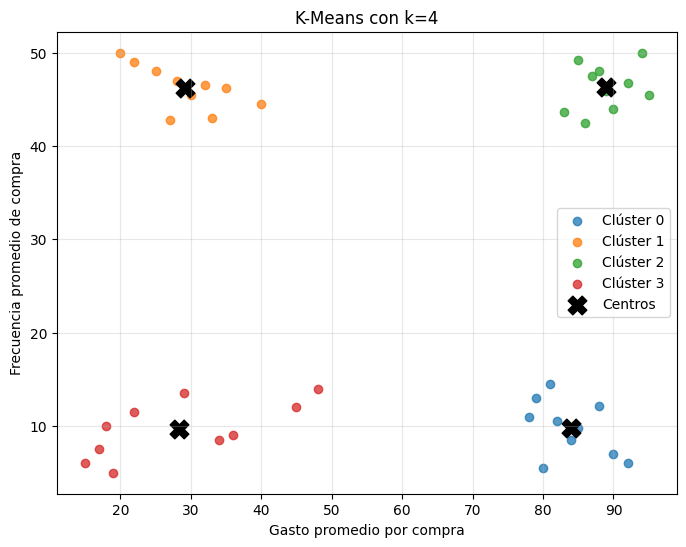

,AverageSpend,AverageFrequency
Clúster,,
0,83.9,9.8
1,29.2,46.2
2,88.9,46.3
3,28.3,9.7


In [7]:
clientes['Cluster'] = km.labels_
perfil = pd.DataFrame(escala.inverse_transform(centros), columns=features).round(1)
perfil.index.name = 'Clúster'

fig, eje = plt.subplots(figsize=(8, 6))
for c in range(k_mejor):
    g = clientes[clientes['Cluster'] == c]
    eje.scatter(g['AverageSpend'], g['AverageFrequency'], alpha=0.75, label=f'Clúster {c}')
eje.scatter(perfil['AverageSpend'], perfil['AverageFrequency'], c='black', marker='X', s=180, label='Centros')
eje.set_xlabel('Gasto promedio por compra'); eje.set_ylabel('Frecuencia promedio de compra')
eje.set_title(f'K-Means con k={k_mejor}')
eje.legend(); eje.grid(alpha=0.3)
plt.savefig('../imagenes/clustering-segmentos.png', dpi=110, bbox_inches='tight')
plt.show()
perfil

## Casos de prueba del ejercicio

Una diferencia práctica entre los dos algoritmos: **K-Means puede asignar clientes nuevos** (los compara con sus centros), mientras que la agrupación jerárquica de scikit-learn no tiene `predict`: para incluir a alguien nuevo habría que reagrupar todo. Para un modelo que se va a usar en una aplicación, eso decide la elección.

In [8]:
casos = pd.DataFrame({'AverageSpend': [21.0, 46.9], 'AverageFrequency': [105.0, 2.0]}, index=['Caso 1', 'Caso 2'])
casos['Clúster'] = km.predict(escala.transform(casos[features]))
casos['Dist. a su centro'] = np.linalg.norm(escala.transform(casos[features]) - centros[casos['Clúster']], axis=1).round(2)
casos

,AverageSpend,AverageFrequency,Clúster,Dist. a su centro
Caso 1,21.0,105.0,1,3.20
Caso 2,46.9,2.0,3,0.75


## Conclusiones

- **k = 4, con acuerdo total entre criterios.** La silueta alcanza su máximo en k=4 (0.810) y la curva del codo se dobla ahí (WCSS de 20.5 a 3.0).
- **Los dos algoritmos encuentran exactamente los mismos grupos.** Misma silueta para k de 2 a 5, y la tabla cruzada en k=4 es una correspondencia perfecta, 10 a 10. Cuando los grupos están tan bien separados, el algoritmo deja de importar.
- **Se elige K-Means** por una razón práctica, no de métrica: puede asignar clientes nuevos con `predict`.
- **Los 4 segmentos** son los cuadrantes gasto alto/bajo × frecuencia alta/baja. El clúster 3 (gasto y frecuencia bajos) es el menos compacto: mayor distancia media al centro (0.382) y menor silueta (0.682).
- **Ojo con los casos fuera de rango.** El caso 1 compra con frecuencia 105, el doble del máximo visto en los datos (50). K-Means lo asigna igualmente al clúster 1, pero queda a 3.20 de su centro, más de 4 veces la mayor distancia de cualquier cliente real (0.703). El modelo **siempre** asigna un clúster, aunque el caso no se parezca a ninguno: en una aplicación real convendría marcar estos casos como atípicos en vez de fiarse de la asignación.

**Modelo elegido:** K-Means con k=4.